# Exploratory Data Analysis and Data Quality Assesment

In [88]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All required libraries imported")

All required libraries imported


In [89]:
df = pd.read_csv("../data/raw/ted_talks.csv")
print(df.head())

       speaker_name                                              title  \
0      Alex Gendler           The Egyptian myth of the death of Osiris   
1       Shari Davis  What if you could help decide how the governme...   
2  Nita Mosby Tyler        Want a more just world? Be an unlikely ally   
3      Susan Lupack           The race to decode a mysterious language   
4     Ariel Waldman  The colorful critter world of microbes in Anta...   

  posted_date duration                                               Link  \
0    Jul 2020     3:56  https://www.ted.com/talks/alex_gendler_the_egy...   
1    Jul 2020    10:28  https://www.ted.com/talks/shari_davis_what_if_...   
2    Jul 2020    10:15  https://www.ted.com/talks/nita_mosby_tyler_wan...   
3    Jul 2020     4:24  https://www.ted.com/talks/susan_lupack_the_rac...   
4    Jul 2020     5:56  https://www.ted.com/talks/ariel_waldman_the_co...   

                                       about_speaker  \
0                                   

## Activity 1: Dataset Summary

In [90]:
#Display the number of rows and columns.
print("rows:", df.shape[0], "columns:", df.shape[1])

rows: 2160 columns: 9


In [91]:
# List all column names and their data types.
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   speaker_name   2160 non-null   str  
 1   title          2160 non-null   str  
 2   posted_date    2160 non-null   str  
 3   duration       2160 non-null   str  
 4   Link           2160 non-null   str  
 5   about_speaker  1744 non-null   str  
 6   about_talk     2159 non-null   str  
 7   views          2155 non-null   str  
 8   tags           2153 non-null   str  
dtypes: str(9)
memory usage: 152.0 KB
None


In [92]:
# Generate descriptive statistics.
df.describe()

,speaker_name,title,posted_date,duration,Link,about_speaker,about_talk,views,tags
count,2160,2160,2160,2160,2160,1744,2159,2155,2153
unique,1915,2160,69,890,2160,1629,2159,2155,2066
top,Alex Gendler,The Egyptian myth of the death of Osiris,Sep 2018,4:49,https://www.ted.com/talks/alex_gendler_the_egy...,Alex Rosenthal takes everyday experiences and ...,"Long jealous of his older brother Osiris, the ...","208,703","TED-Ed,animation,education"
freq,31,1,59,11,1,12,1,1,15


In [93]:
# Identify the number of unique talks, where a suitable identifier is available.
print(df.duplicated().sum())

0


## Activity 2: Missing Values and Duplicates

In [94]:
# Calculate missing-value counts and percentages for each column.
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})
print(missing_summary)

               Missing_Count  Missing_Percentage
speaker_name               0            0.000000
title                      0            0.000000
posted_date                0            0.000000
duration                   0            0.000000
Link                       0            0.000000
about_speaker            416           19.259259
about_talk                 1            0.046296
views                      5            0.231481
tags                       7            0.324074


In [95]:
# Identify duplicate rows and repeated talk identifiers, if available.
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [96]:
# Identify missing or empty titles, descriptions, tags, transcripts, and URLs.
print(df.isnull().sum())

speaker_name       0
title              0
posted_date        0
duration           0
Link               0
about_speaker    416
about_talk         1
views              5
tags               7
dtype: int64


### Explain which missing fields may affect the recommendation system.
about_talk will be most affecting the recommendation system but it is missing in just in row so it won't affect much. About speaker will affect the recommendation system if the recommendation system recommends similar speakers.

## Activity 3: Text Analysis

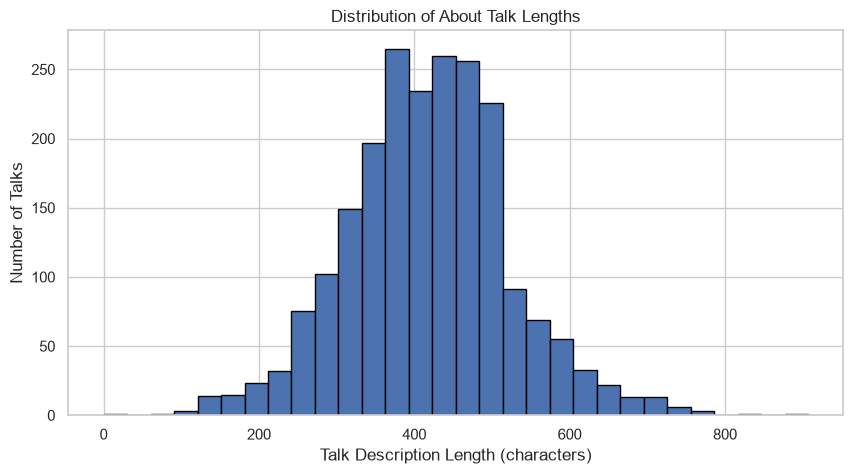

In [97]:
# Analyze transcript and description lengths.
df['talk_len'] = df['about_talk'].fillna('').str.len()
plt.figure(figsize=(10, 5))
plt.hist(df['talk_len'], bins=30, edgecolor='black')
plt.xlabel('Talk Description Length (characters)')
plt.ylabel('Number of Talks')
plt.title('Distribution of About Talk Lengths')
plt.show()

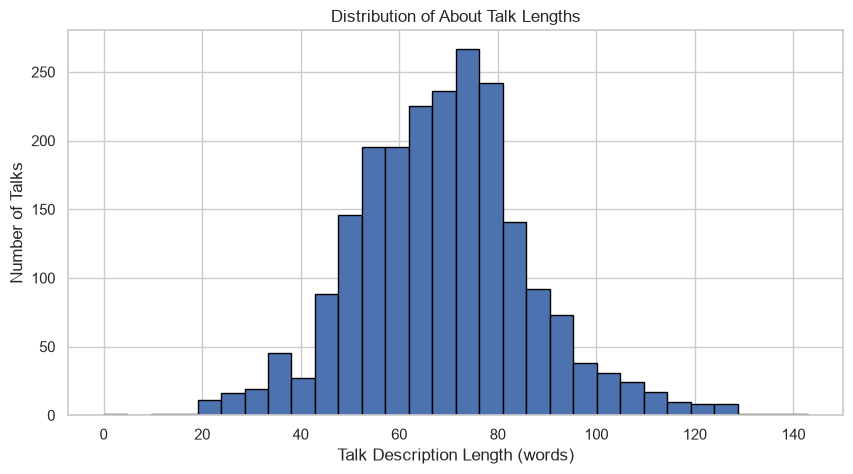

In [98]:
# Calculate word counts.
df['talk_word_count'] = df['about_talk'].fillna('').str.split().str.len()
plt.figure(figsize=(10, 5))
plt.hist(df['talk_word_count'], bins=30, edgecolor='black')
plt.xlabel('Talk Description Length (words)')
plt.ylabel('Number of Talks')
plt.title('Distribution of About Talk Lengths')
plt.show()

In [99]:
#Identify empty or unusually short text entries.
df['talk_id'] = range(1, len(df)+1)
empty_talks = df[
    df['about_talk'].isna() |
    df['about_talk'].fillna('').str.strip().eq('')
]
print("Number of empty entries:", len(empty_talks))
display(empty_talks[['talk_id', 'about_talk']])

Number of empty entries: 1


,talk_id,about_talk
1954,1955,NaN


Transcriptions are not available in the given dataset and hence we won't be able to analyze the transcripts

## Activity 4: Tag and Topic Analysis

In [100]:
# Identify the most frequently occurring TED Talk tags or topics.
print(df['tags'].head())

0    education,ancient world,TED-Ed
1    democracy,leadership,community
2          activism,inequality,race
3         TED-Ed,education,language
4       science,animals,exploration
Name: tags, dtype: str


In [101]:
# Display the top 10–15 tags in a chart.
from collections import Counter
# Split comma-separated strings into individual tags
all_tags = (
    df['tags']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)
# Count individual tags and sort by frequency
tag_counts = all_tags.value_counts()
# Display top 10 most frequent individual tags
print("Top 10 most frequently occurring tags across all TED Talks")
print(tag_counts.head(10))

Top 10 most frequently occurring tags across all TED Talks
tags
TED-Ed           331
animation        207
education        152
communication    152
activism         147
science          145
health           127
history          119
art              117
community        112
Name: count, dtype: int64


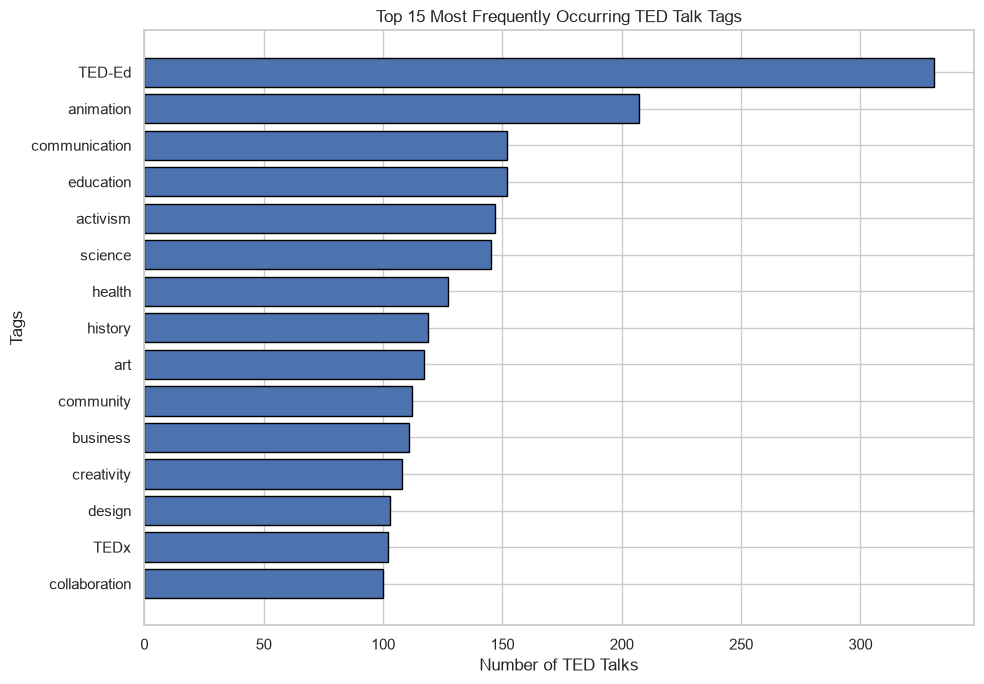

In [102]:
# Select top 15 tags and sort for horizontal plotting
top_tags = tag_counts.head(15).sort_values(ascending=True)
# Create the chart
plt.figure(figsize=(10, 7))
plt.barh(top_tags.index, top_tags.values, edgecolor='black')
plt.xlabel('Number of TED Talks')
plt.ylabel('Tags')
plt.title('Top 15 Most Frequently Occurring TED Talk Tags')
plt.tight_layout()
plt.show()

### Explain which topics appear most frequently.
The topics appearing most freqently include animation, communication, education, activism and so on. These are most frequently apprearing topics as they have been used in the tags most frequently

### Document the format in which tags are stored and how they were processed.
Tags Storage and Processing: The tags column stores multiple tags as comma-separated strings. Missing values were excluded, strings were split into individual tags, whitespace was removed, and tag frequencies were calculated using value_counts(). The top 15 most frequent tags were visualized in a horizontal bar chart.

## Activity 5: Additional Data Analysis

In [103]:
# Generate descriptive statistics.
duration_parts = df['duration'].astype('string').str.strip().str.extract(
    r'^(\d+):(\d{1,2})$'
)

df['duration_seconds'] = (
    pd.to_numeric(duration_parts[0], errors='coerce') * 60
    + pd.to_numeric(duration_parts[1], errors='coerce')
)
df[['views', 'duration_seconds']].describe()

,duration_seconds
count,2155.0
mean,659.196752
std,340.526498
min,60.0
25%,343.5
50%,682.0
75%,863.5
max,3503.0


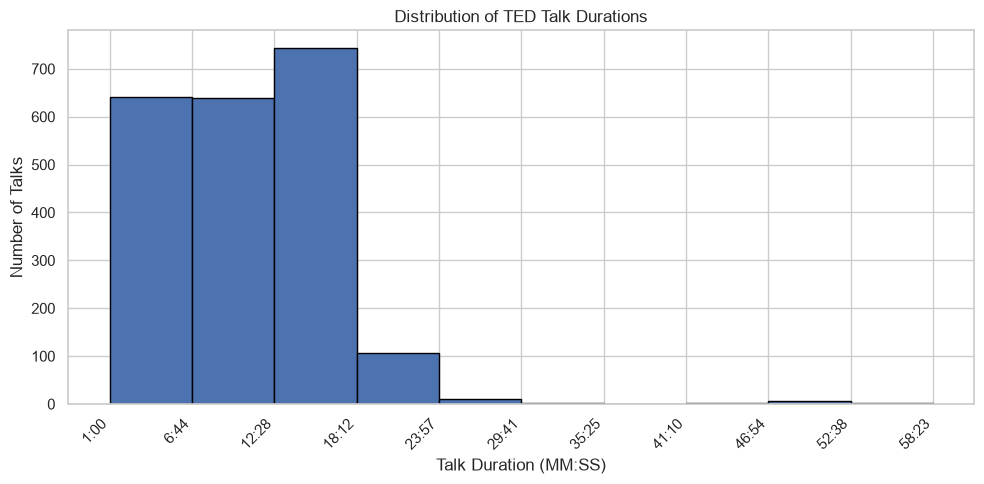

In [104]:
# Visualize their distributions.
duration = df['duration_seconds'].dropna()

if duration.empty:
    print("No valid duration values found. Check the original duration column.")
else:
    _, edges = np.histogram(duration, bins=10)

    plt.figure(figsize=(10, 5))
    plt.hist(duration, bins=edges, edgecolor='black')

    plt.xlabel('Talk Duration (MM:SS)')
    plt.ylabel('Number of Talks')
    plt.title('Distribution of TED Talk Durations')

    plt.xticks(
        edges,
        [f'{int(x // 60)}:{int(x % 60):02d}' for x in edges],
        rotation=45,
        ha='right'
    )

    plt.tight_layout()
    plt.show()

In [105]:
print(df['views'].head())

0    208,703
1    425,688
2    460,269
3    350,202
4    333,482
Name: views, dtype: str


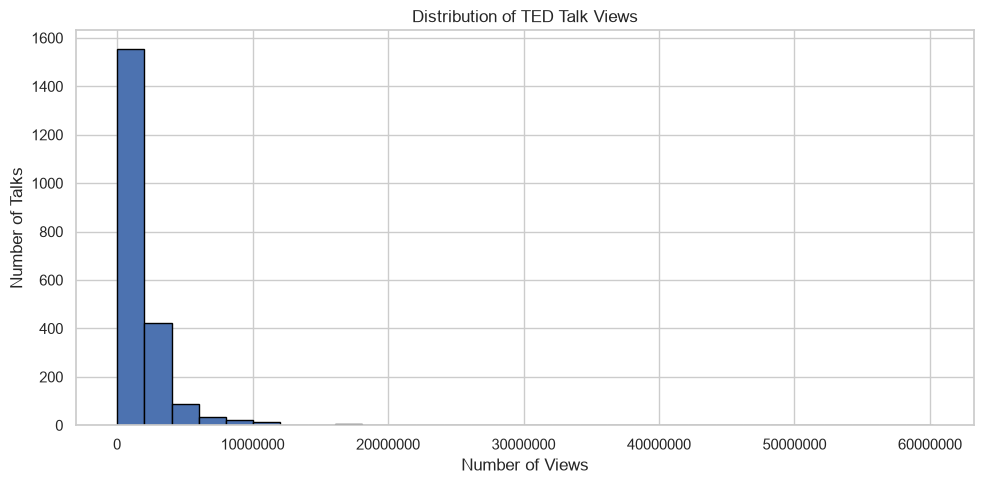

In [106]:
# Remove commas and convert to numeric
df['views'] = pd.to_numeric(
    df['views'].str.replace(',', '', regex=False),
    errors='coerce'
)

# Plot distribution
views = df['views'].dropna()

plt.figure(figsize=(10, 5))
plt.hist(views, bins=30, edgecolor='black')

plt.xlabel('Number of Views')
plt.ylabel('Number of Talks')
plt.title('Distribution of TED Talk Views')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

### Identify unusual values or patterns.
Views and duration both are highly right skewed and not properly distributed data

### Record your observations
It descriptive statistics of data was recorded and data visualizations were observed and it was found out that both views and duration were highly skewed.